# Homework 4: Evaluation

This notebook evaluates a logistic regression model for course lead conversion. It uses a fixed train, validation, and test split for the threshold exercises, then uses five-fold cross-validation on the full training portion for model evaluation and regularization tuning.

## Data loading and preparation

The data is split into an 80% training portion and a 20% held-out test portion. The training portion is then divided into training and validation subsets, producing 60% / 20% / 20% train / validation / test shares. Missing categorical values are filled with `NA` and missing numerical values with `0.0`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import KFold, train_test_split

DATA_URL = (
    "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/"
    "main/cohorts/2026/data/course_lead_scoring_2026.csv"
)
TARGET = "converted"

df = pd.read_csv(DATA_URL)
if TARGET not in df.columns:
    raise ValueError(f"The dataset does not contain the target column '{TARGET}'.")

categorical_columns = df.select_dtypes(include=["object", "category", "string"]).columns
numerical_columns = df.select_dtypes(include=[np.number]).columns
df[categorical_columns] = df[categorical_columns].fillna("NA")
df[numerical_columns] = df[numerical_columns].fillna(0.0)

df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1,
)
df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1,
)

feature_columns = [column for column in df.columns if column != TARGET]
numerical_features = [
    column for column in numerical_columns if column != TARGET
]

print(f"Dataset rows: {len(df):,}")
print(
    "Split sizes: "
    f"train={len(df_train):,}, validation={len(df_val):,}, "
    f"test={len(df_test):,}"
)
print(f"Target prevalence in training data: {df_train[TARGET].mean():.3f}")

Dataset rows: 5,000
Split sizes: train=3,000, validation=1,000, test=1,000
Target prevalence in training data: 0.576


## Q1: ROC AUC feature importance

For each numerical feature, calculate ROC AUC by treating the feature values as scores. AUC values below 0.5 are recalculated with the sign reversed so that larger reported values indicate the better scoring direction.

In [2]:
feature_auc = {}
y_train = df_train[TARGET]

for column in numerical_features:
    auc = roc_auc_score(y_train, df_train[column])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[column])
    feature_auc[column] = auc

requested_features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income",
]
missing_requested_features = [
    column for column in requested_features if column not in feature_auc
]
if missing_requested_features:
    raise ValueError(
        "Expected numerical feature(s) were not found: "
        + ", ".join(missing_requested_features)
    )

for column in requested_features:
    print(f"{column}: {feature_auc[column]:.3f}")

best_feature = max(feature_auc, key=feature_auc.get)
print(f"Highest ROC AUC feature: {best_feature} ({feature_auc[best_feature]:.3f})")

lead_score: 0.788
number_of_courses_viewed: 0.723
interaction_count: 0.765
annual_income: 0.608
Highest ROC AUC feature: lead_score (0.788)


## Q2: Train the logistic regression model

Fit a `DictVectorizer` on the training features and use it to transform the validation features. The validation ROC AUC is calculated from the model's positive-class probabilities.

In [3]:
X_train = df_train[feature_columns]
X_val = df_val[feature_columns]
y_train = df_train[TARGET]
y_val = df_val[TARGET]

dv = DictVectorizer(sparse=False)
X_train_dict = dv.fit_transform(X_train.to_dict(orient="records"))
X_val_dict = dv.transform(X_val.to_dict(orient="records"))

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train_dict, y_train)
y_val_probability = model.predict_proba(X_val_dict)[:, 1]
validation_auc = roc_auc_score(y_val, y_val_probability)

print(f"Validation ROC AUC: {validation_auc:.3f}")

Validation ROC AUC: 0.732


## Q3: Precision and recall

Calculate precision and recall using probability thresholds from 0.00 through 1.00 in increments of 0.01. The reported threshold minimizes the absolute difference between precision and recall, excluding thresholds where both metrics are zero.

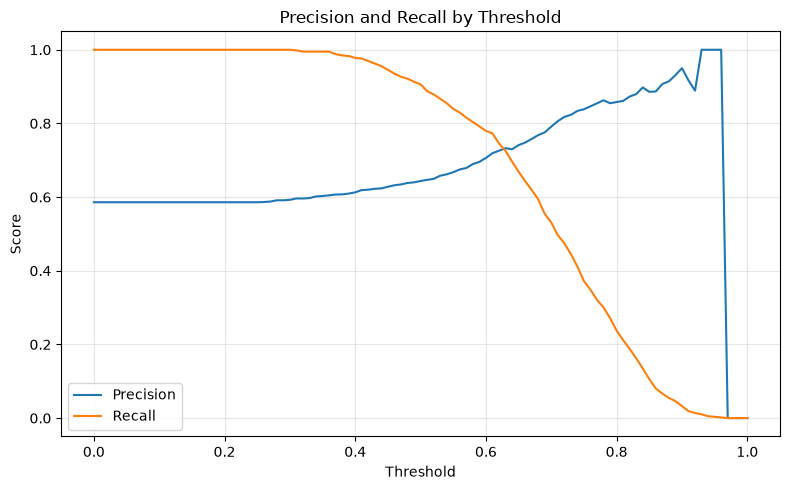

Threshold where precision and recall are closest: 0.63 (precision=0.733, recall=0.725)


In [4]:
thresholds = np.round(np.arange(0.0, 1.01, 0.01), 2)
precision_values = []
recall_values = []

for threshold in thresholds:
    y_val_prediction = (y_val_probability >= threshold).astype(int)
    precision_values.append(
        precision_score(y_val, y_val_prediction, zero_division=0)
    )
    recall_values.append(recall_score(y_val, y_val_prediction, zero_division=0))

precision_values = np.asarray(precision_values)
recall_values = np.asarray(recall_values)
valid_thresholds = (precision_values != 0) | (recall_values != 0)
if not np.any(valid_thresholds):
    raise ValueError("No threshold produced a non-zero precision or recall.")

difference = np.abs(precision_values - recall_values)
difference[~valid_thresholds] = np.inf
intersection_index = int(np.argmin(difference))
intersection_threshold = thresholds[intersection_index]

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision_values, label="Precision")
plt.plot(thresholds, recall_values, label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall by Threshold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(
    f"Threshold where precision and recall are closest: "
    f"{intersection_threshold:.2f} "
    f"(precision={precision_values[intersection_index]:.3f}, "
    f"recall={recall_values[intersection_index]:.3f})"
)

## Q4: F1 score

Compute the F1 score at every threshold from 0.00 to 1.00. `zero_division=0` gives an F1 score of zero when a threshold produces no positive predictions and the score would otherwise be undefined.

In [5]:
f1_values = []
for threshold in thresholds:
    y_val_prediction = (y_val_probability >= threshold).astype(int)
    f1_values.append(f1_score(y_val, y_val_prediction, zero_division=0))

f1_values = np.asarray(f1_values)
best_f1_index = int(np.argmax(f1_values))
best_f1_threshold = thresholds[best_f1_index]

print(
    f"Threshold with maximum F1 score: {best_f1_threshold:.2f} "
    f"(F1={f1_values[best_f1_index]:.3f})"
)

Threshold with maximum F1 score: 0.41 (F1=0.758)


## Q5: Five-fold cross-validation

Use shuffled five-fold cross-validation on `df_full_train`. Each fold fits its own `DictVectorizer` using only the fold's training rows. The standard deviation is the population standard deviation of the five validation ROC AUC scores.

In [6]:
def cross_validation_auc_scores(data, c_value):
    """Return the validation ROC AUC for each fold."""
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    feature_names = [column for column in data.columns if column != TARGET]

    for train_indices, val_indices in kfold.split(data):
        fold_train = data.iloc[train_indices]
        fold_val = data.iloc[val_indices]
        fold_train_features = fold_train[feature_names]
        fold_val_features = fold_val[feature_names]

        fold_vectorizer = DictVectorizer(sparse=False)
        fold_train_matrix = fold_vectorizer.fit_transform(
            fold_train_features.to_dict(orient="records")
        )
        fold_val_matrix = fold_vectorizer.transform(
            fold_val_features.to_dict(orient="records")
        )

        fold_model = LogisticRegression(
            solver="liblinear",
            C=c_value,
            max_iter=1000,
        )
        fold_model.fit(fold_train_matrix, fold_train[TARGET])
        fold_probability = fold_model.predict_proba(fold_val_matrix)[:, 1]
        scores.append(roc_auc_score(fold_val[TARGET], fold_probability))

    return scores


cv_scores_c1 = cross_validation_auc_scores(df_full_train, c_value=1.0)
cv_std_c1 = float(np.std(cv_scores_c1))
print(f"Five-fold ROC AUC standard deviation (C=1): {cv_std_c1:.3f}")

Five-fold ROC AUC standard deviation (C=1): 0.007


## Q6: Hyperparameter tuning

Evaluate each requested regularization strength using the same shuffled five-fold procedure. Select the value with the highest mean ROC AUC; ties are resolved by the lowest standard deviation and then the smallest `C`.

In [7]:
c_values = [0.000001, 0.001, 1]
cv_results = []

for c_value in c_values:
    scores = cross_validation_auc_scores(df_full_train, c_value=c_value)
    mean_auc = float(np.mean(scores))
    std_auc = float(np.std(scores))
    cv_results.append(
        {
            "C": c_value,
            "mean_auc": mean_auc,
            "std_auc": std_auc,
        }
    )
    print(f"C={c_value}: mean ROC AUC={mean_auc:.3f}, std={std_auc:.3f}")

best_result = sorted(
    cv_results,
    key=lambda result: (-result["mean_auc"], result["std_auc"], result["C"]),
)[0]
print(f"Selected C: {best_result['C']}")

C=1e-06: mean ROC AUC=0.617, std=0.019
C=0.001: mean ROC AUC=0.749, std=0.010
C=1: mean ROC AUC=0.732, std=0.007
Selected C: 0.001
